# Week 6 – Medical Imaging: Pneumonia detection from chest X-rays
**Lab 6 · Project 2 · Applied Computer Vision**

Dataset: [Chest X-Ray Images (Pneumonia) – Paul Mooney](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia)

**Before running:** Settings panel (right) → *Accelerator* = **GPU T4**, *Internet* = **On**, and the dataset is added under *Input*.

## Part 0: Configuration cell
This is the only cell to change for another dataset.

In [1]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
DATA_ROOT = '/kaggle/input/chest-xray-pneumonia/chest_xray'
TRAIN_DIR = f'{DATA_ROOT}/train'      # folder with one subfolder per class
TEST_DIR = f'{DATA_ROOT}/test'        # None if your dataset has no test set
GRAYSCALE = True                      # True for X-rays, castings, scans
IMG_SIZE = 224
BACKBONE = 'resnet18'     # or 'resnet50', 'efficientnet_b0'
GROUP_PATTERN = r'(person\d+|IM-\d+|NORMAL2-IM-\d+)'   # None if no groups
POSITIVE = 'PNEUMONIA'                # binary tasks: the class you must catch
TARGET_RECALL = 0.95                  # binary tasks: recall you must reach
# ======================================================================

# Kaggle may mount the dataset elsewhere: find the real 'train' folder automatically
import os, glob
if not os.path.isdir(TRAIN_DIR):
    hits = [d for d in glob.glob('/kaggle/input/**/train', recursive=True)
            if '__MACOSX' not in d and os.path.isdir(os.path.join(d, POSITIVE))]
    if not hits:
        for root, dirs, files in os.walk('/kaggle/input'):   # show what IS there
            if root.count(os.sep) <= 5:
                print(root, dirs[:6], len(files), 'files')
        raise SystemExit('No train/PNEUMONIA folder found: add the Paul Mooney DATASET (not a notebook).')
    DATA_ROOT = os.path.dirname(sorted(hits, key=len)[0])
    TRAIN_DIR, TEST_DIR = f'{DATA_ROOT}/train', f'{DATA_ROOT}/test'
print('TRAIN_DIR:', TRAIN_DIR, os.listdir(TRAIN_DIR))
print('TEST_DIR :', TEST_DIR, os.listdir(TEST_DIR))

TRAIN_DIR: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/train ['NORMAL', 'PNEUMONIA']
TEST_DIR : /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/test ['NORMAL', 'PNEUMONIA']


In [2]:
import os, re, time, copy, hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must print cuda

Device: cuda


In [3]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda; if it says cpu, turn on GPU T4 in Settings

Device: cuda


## Part 1: Index and audit the dataset
### Task 1.1: One row per image
I created one table row for each image, including its file path, class label, filename, and patient group. The training folder contains 1,341 NORMAL images and 3,875 PNEUMONIA images, so PNEUMONIA is about 2.9 times more common. The filename pattern identified a group for every image, and the dataset averages 1.83 images per group.

In [4]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

label
NORMAL       1341
PNEUMONIA    3875
Imbalance ratio (max / min): 2.9
Images per group: 1.83


In [5]:
# Sanity check of GROUP_PATTERN (Common Issues table): every row should show an id, not NaN
print(train_df[['file', 'group']].sample(8, random_state=3).to_string(index=False))
print('Files that matched no group id:', train_df['file'].str.extract(GROUP_PATTERN, expand=False).isna().sum())

                         file      group
            IM-0482-0001.jpeg    IM-0482
       IM-0656-0001-0002.jpeg    IM-0656
person1327_bacteria_3373.jpeg person1327
person1674_bacteria_4437.jpeg person1674
person1507_bacteria_3942.jpeg person1507
   person1344_virus_2320.jpeg person1344
    person594_virus_1145.jpeg  person594
 person364_bacteria_1660.jpeg  person364
Files that matched no group id: 0


### Task 1.2: What do the images look like?
I inspected 300 sample images. Most were grayscale: 286 had grayscale mode and 14 were RGB. Image sizes varied considerably: the median was 1,300 × 890 pixels, while the smallest and largest dimensions ranged from 384 × 127 to 2,510 × 2,543 pixels. The notebook converts images to grayscale and resizes them before model training.

          w       h
min   384.0   127.0
50%  1300.0   890.0
max  2510.0  2543.0
Colour modes: {'L': 286, 'RGB': 14}


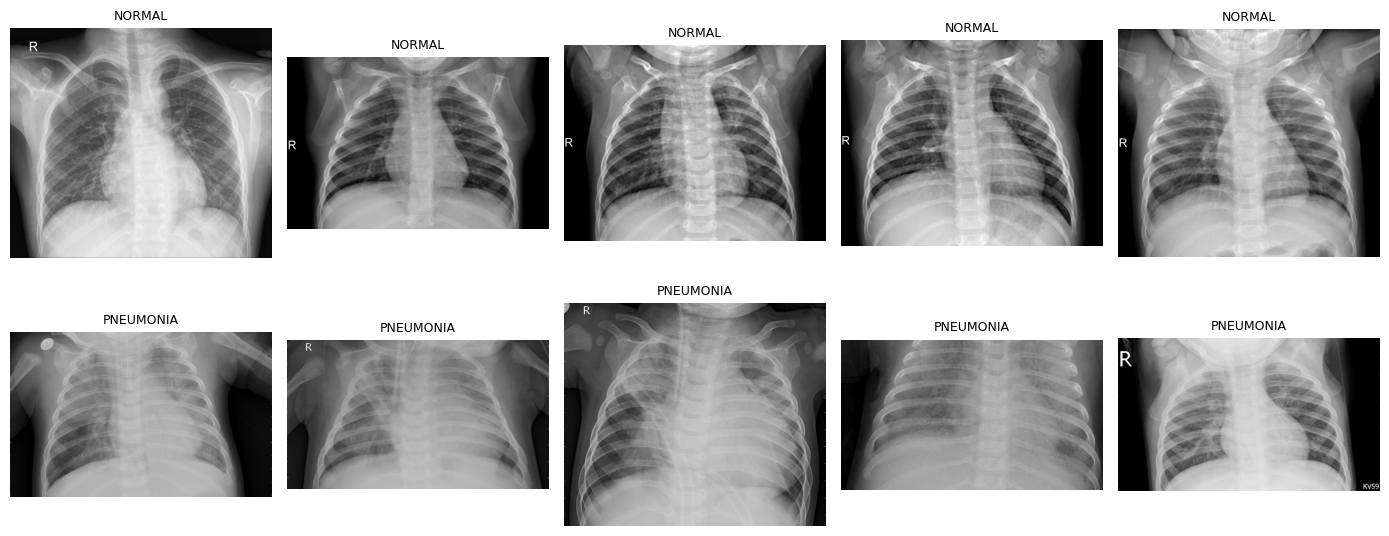

In [6]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## Part 2: Leakage audit
### Task 2.1: Exact and near-duplicates

In [7]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))

if TEST_DIR:
    T = np.stack([fingerprint(p) for p in all_df['path']])
    tr = T[(all_df.split == 'train').values]
    te = T[(all_df.split == 'test').values]
    d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
    near = d_min < 0.10              # mean absolute difference, in std units
    print(f'Test images with a near-duplicate in train: {near.sum()} '
          f'of {len(te)}')
    print('Closest distances:', np.sort(d_min)[:5].round(3))

Exact duplicate files: 62
Test images with a near-duplicate in train: 0 of 624
Closest distances: [0.164 0.17  0.172 0.173 0.174]


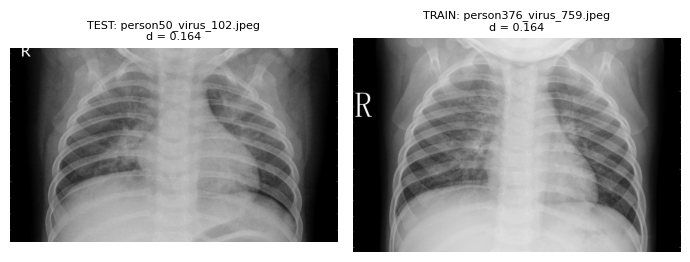

split     label                           file                              md5
 test    NORMAL NORMAL2-IM-0246-0001-0002.jpeg 05c43c853e8209bf0423f73a6f0a8c58
 test    NORMAL NORMAL2-IM-0246-0001-0001.jpeg 05c43c853e8209bf0423f73a6f0a8c58
train PNEUMONIA  person1619_bacteria_4268.jpeg 061c1fac2e79c2d435a6d4c1e35894e7
train PNEUMONIA  person1619_bacteria_4267.jpeg 061c1fac2e79c2d435a6d4c1e35894e7
train PNEUMONIA  person1349_bacteria_3436.jpeg 077fce04eafc798401239d127a84f5f0
train PNEUMONIA  person1349_bacteria_3437.jpeg 077fce04eafc798401239d127a84f5f0
train PNEUMONIA  person1481_bacteria_3867.jpeg 23cd1cdafc40ad7f67e6d076ffec52ab
train PNEUMONIA  person1481_bacteria_3866.jpeg 23cd1cdafc40ad7f67e6d076ffec52ab
train PNEUMONIA       person357_virus_734.jpeg 23d698733d4709babc2bf0b40ea67cf4
train PNEUMONIA       person357_virus_735.jpeg 23d698733d4709babc2bf0b40ea67cf4


In [8]:
# Inspect before deleting anything: show flagged pairs side by side (test image | closest train image)
if TEST_DIR:
    tr_paths = all_df[all_df.split == 'train']['path'].values
    te_paths = all_df[all_df.split == 'test']['path'].values
    flagged = np.argsort(d_min)[:min(4, max(int(near.sum()), 1))]   # the closest pairs
    fig, axes = plt.subplots(len(flagged), 2, figsize=(7, 3.2 * len(flagged)))
    axes = np.atleast_2d(axes)
    for row, k in zip(axes, flagged):
        j = np.abs(tr - te[k]).mean(axis=1).argmin()
        for ax, p, t in zip(row, [te_paths[k], tr_paths[j]], ['TEST', 'TRAIN']):
            ax.imshow(Image.open(p).convert('RGB'))
            ax.set_title(f'{t}: {os.path.basename(p)}\nd = {d_min[k]:.3f}', fontsize=8)
            ax.axis('off')
    plt.tight_layout()
    plt.show()
if len(exact):
    print(exact.sort_values('md5')[['split', 'label', 'file', 'md5']].head(10).to_string(index=False))

### Task 2.2: Split by group

In [9]:
# Validation split BY GROUP: no patient appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                  # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))   # must be 0
print(va_df['label'].value_counts().to_string())

train 4354 | val 862 | test 624
Groups shared by train and val: 0
label
PNEUMONIA    646
NORMAL       216


I used weighted loss rather than a balanced sampler. The training split has 4,354 images: 1,125 NORMAL and 3,229 PNEUMONIA.

For NORMAL, the weight is `4,354 / (2 × 1,125) = 1.935`. For PNEUMONIA, it is `4,354 / (2 × 3,229) = 0.674`. The higher NORMAL weight gives the less common class more influence during training.

I kept random resized crops, small rotations, and modest brightness and contrast changes to represent small differences in framing and exposure. I avoided horizontal and vertical flips because they can change the left-right orientation of an X-ray.

## Part 3: Transforms and imbalance
### Task 3.1: Datasets and transforms

In [10]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)

### Task 3.2: Class weights or balanced sampling

In [11]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print(dict(zip(classes, class_w.round(3))))
print('N =', len(train_ds), '| K =', len(classes), '| n_c =', dict(zip(classes, n_c)))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

{'NORMAL': np.float64(1.935), 'PNEUMONIA': np.float64(0.674)}
N = 4354 | K = 2 | n_c = {'NORMAL': np.int64(1125), 'PNEUMONIA': np.int64(3229)}


The best validation macro-F1 was 0.881 after training only the new classification head. After fine-tuning the final ResNet block, the best validation macro-F1 increased to 0.945, so fine-tuning helped in this run.

Each epoch took about 68–70 seconds. The validation score peaked during the first fine-tuning epoch and then fell in the next two epochs. With more time, I would try one or two additional epochs with early stopping, while keeping the best validation checkpoint.

## Part 4: Build and train
### Task 4.1: Backbone with a new head

In [12]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s] 


resnet18 trainable: 1026


### Task 4.2: Two-phase training, selected by macro-F1

In [13]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')   # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
best1 = fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
best2 = fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
                    {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)
print(f'Best val macro-F1: phase 1 {best1:.3f} | phase 2 {best2:.3f}')

Phase 1: head only
epoch 1: val macro-F1 0.847 (68s)
epoch 2: val macro-F1 0.881 (68s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.945 (70s)
epoch 2: val macro-F1 0.941 (70s)
epoch 3: val macro-F1 0.916 (69s)
Best val macro-F1: phase 1 0.881 | phase 2 0.945


## Part 5: Test once, and set the threshold
### Task 5.1: Test-set report

              precision    recall  f1-score   support

      NORMAL      0.970     0.825     0.891       234
   PNEUMONIA      0.904     0.985     0.942       390

    accuracy                          0.925       624
   macro avg      0.937     0.905     0.917       624
weighted avg      0.928     0.925     0.923       624

Macro-F1: 0.917


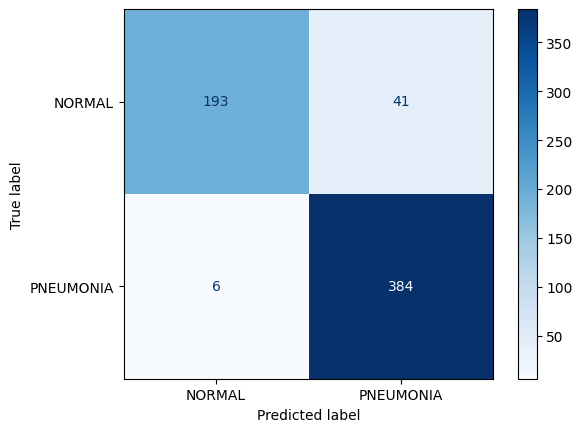

In [14]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()

### Task 5.2: Threshold for a target recall (binary tasks)
The threshold is chosen on **validation** data, then applied once to the test set.

In [15]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]   # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')

    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f}   Specificity {tn / (tn + fp):.3f}'
          f'   PPV {tp / max(tp + fp, 1):.3f}')
    print(f'TP {tp}  FN {fn}  TN {tn}  FP {fp}  | test prevalence {yt.mean():.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.362
Test AUC 0.979
Sensitivity 0.990   Specificity 0.808   PPV 0.896
TP 386  FN 4  TN 189  FP 45  | test prevalence 0.625


**At the test-set prevalence of 62.5%:**

PPV = (0.990 × 0.625) / ((0.990 × 0.625) + ((1 − 0.808) × (1 − 0.625)))

PPV = 0.61875 / (0.61875 + 0.072)  
PPV ≈ **0.896, or 89.6%**

**At a realistic screening prevalence of 5%:**

PPV = (0.990 × 0.05) / ((0.990 × 0.05) + ((1 − 0.808) × (1 − 0.05)))

PPV = 0.0495 / (0.0495 + 0.1824)  
PPV ≈ **0.213, or 21.3%**

The test macro-F1 was 0.917. NORMAL was the weaker class by recall at 0.825; PNEUMONIA recall was 0.985. I chose a threshold of 0.362 on the validation set to target recall of at least 0.95. On the test set, sensitivity was 0.990 and specificity was 0.808, so test recall exceeded the target. Test AUC was 0.979.

At the test-set prevalence of 62.5%, PPV was 89.6%. At a 5% prevalence, PPV falls to 21.3%. When pneumonia is less common, false positives make up a larger share of positive predictions, even though sensitivity and specificity are unchanged.

## Part 6: Grad-CAM shortcut check

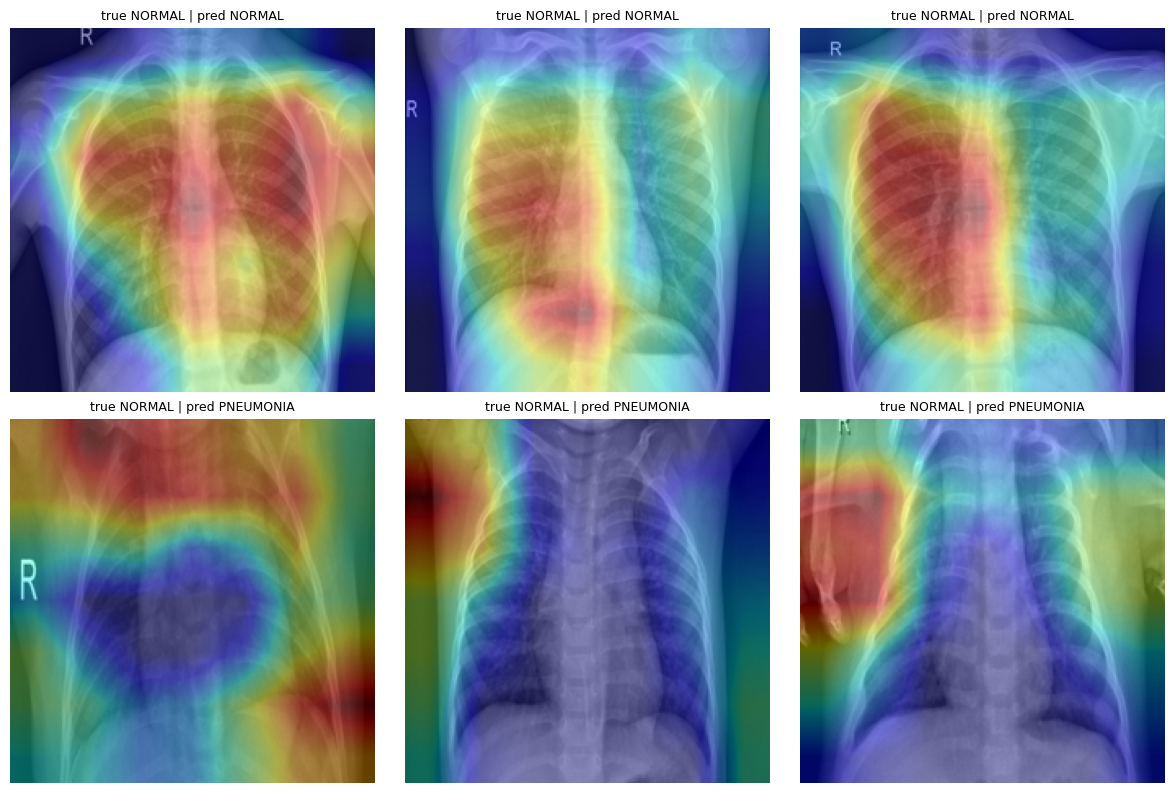

In [16]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)   # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()  # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig('/kaggle/working/gradcam.png', dpi=150)   # for the README and LinkedIn post
plt.show()

1. The heatmap covers much of the central chest and both lung fields. That is relevant anatomy, although the activation is broad.
2. The strongest activation is around the central lung region. That is a plausible area for the model to use.
3. The heatmap is concentrated over the lung field on the left side of the displayed image. That is relevant anatomy.
4. This NORMAL image was predicted as PNEUMONIA. The heatmap is strongest near the upper chest and shoulder area, so the highlighted evidence is not clearly a specific lung finding.
5. This NORMAL image was predicted as PNEUMONIA. A strong hotspot appears near the left edge of the displayed image, which is suspicious because it is not clearly inside the lung.
6. This NORMAL image was also predicted as PNEUMONIA. The strongest activation is near the side edge and upper chest, so it could reflect an image-border feature rather than a reliable disease pattern.

My verdict is **shortcut suspected, not confirmed**. Grad-CAM does not prove why a model made a prediction. I would mask possible corner markers and image borders, retrain the model, and compare its performance and heatmaps on the same patient-grouped split.

## Part 7: Save and document

In [17]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt
